# QPDK vortex neck test chip — four λ/4 resonators shorted through narrow necks (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/vortex_neck_test_chip.pic.yml`, with the
cells `qpdk/cells/vortex.py` (`neck_termination`) and `qpdk/cells/resonator.py` (`resonator_coupled`),
<https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024; depth-1 clone read 2026-11-03,
never executed). Spec: `docs/designs/qpdk/vortex_neck_test_chip.md`. The geometry follows Shulga *et al.* (2026,
single-vortex observation): the neck sits at the current antinode, so one trapped vortex shifts the resonance.

One straight feedline with four hanger resonators alternating below and above it. Each resonator is **open at its
coupled end**; its far end runs into a `neck_termination`: the centre conductor tapers over 100 µm from 10 µm to a
2 µm, 325 µm-long neck that joins the ground plane at the far edge of a 380 µm-wide etched window. Lengths are
4000 µm + 600 / −300 / +300 / 0 µm.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 4.8 × 5.6 mm chip area, launchers on its edge | the 7.5 × 7.5 mm Quantcore die (`QP.die_box(4800, 5600)`, centred on the source's chip area, so every source coordinate is kept + (100, 2800) µm), Quantcore die frame, device ID "QPDK-VNT" |
| pads | QPDK `launcher` on the chip area's west and east edges | the same `BondPad`s moved to **100 µm** from the die edge (`frame.pad_edge`, `edge="auto"`): 1250 µm out each, so the feedline is 2.5 mm longer |
| substrate | Al on Si (εr 11.45) | Nb on sapphire 650 µm, εr 10.25: the frequencies are not QPDK's |
| junctions | none | none |
| cheese | none (the vortex-trap holes are part of each neck window; no fill) | the PDK band (chip `cheese` `"auto"`), at least 4 µm clear of 3/0; the trap holes stay in the cell |
| elements, positions | — | kept: the necks at the source's placement, the coupled sections at the source's x, the resonator lengths |
| placement | the source's chip area | centred (checked below, no shift) |

**Reproduced:**
- The neck and coupled-section positions (Designer = source + (100, 2800) µm). The coupled sections are 200 µm long
  with a 20 µm gap edge to edge (→ an 8 µm ground strip), at source x 1006 / 1706 / 2606 / 3306 µm, open at the
  west end; they are pinned by position (`near=`), so they stay put when the pads move.
- **The necks:** `NeckTermination` (Quantcore re-implementation of QPDK `neck_termination`, MIT) with the QPDK
  defaults: 10 → 2 µm linear taper over 100 µm, 2 × 325 µm neck shorted at the far edge of a 380 × 425 µm etched
  window, 4 rows of 4 µm vortex-trap holes (pitch 5.5 µm, 6 µm from the window, a 24 µm hole-free column on the
  neck axis). Port `o1` at the source's neck placement (source x, ∓2200 µm), rotation ∓90° as in the YAML.
- **The lead lengths, computed from the QPDK cells (QPDK was not run):** `resonator(length=L, meanders=6)` with the
  `cpw` bend radius 100 µm has 6 half-turns (100π µm each) and 7 equal straights, so `resonator_o2` sits 1200 µm
  beyond `resonator_o1` and (L − 600π)/7 µm east of it, facing east. Every neck is 150.06 µm further east and
  970 µm further out, so each `route_bundle_cpw` lead is one 90° `bend_circular`:
  150.06 + 970 − 2·100 + 50π = **1077.1 µm**. Each route is therefore L + 1077.1 µm, from `N.o1` to the open end
  (the neck adds its own 425 µm).

**Substituted / estimated:**
- The meander shape: the router's KQC `Meander` between the neck and the coupled section, instead of QPDK's 6-turn
  meander hanging from the coupled section plus an L-shaped lead. The length is the same (printed below).
- The neck's LOM is the `NeckTermination` model: the taper + neck as a series line at its inductive-equivalent
  length (ℓ·L′/L′_cpw; the 425 µm drawn ≈ 1279 µm of 10/6 µm CPW), shorted at the window edge. This is a **rough,
  geometric-only estimate**: it has no kinetic inductance, which for a 2 µm Nb neck (and QPDK's Al) adds more.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the two launchers, the feedline, the four neck terminations (this chip has no qubits), the four λ/4 resonators from the necks to their hangers on the feedline, and then the whole chip (the sim group, the centring check, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `vortex_neck_test_chip.v1.ipynb`; both save the same `vortex_neck_test_chip.json`.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK
notebooks (launcher, the die box). `FULL_FAB = False` skips the fab-only corner rounding in Fab 1 (`qcc mask`
writes the full file). The segment pictures go to `build/snapshots/vortex_neck_test_chip/` (not kept in the
repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
import _qpdk as QP                               # QPDK cell defaults, die box

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/qpdk")                           # design JSON + final snapshots
STEPS = Path("build/snapshots/vortex_neck_test_chip")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack (resonator frequencies), the frame and pad rule and the
cheese / 3/0 rules.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, then what
hangs on it, and the whole chip. A vortex-neck test chip has no qubits, so segment 4 places the necks (the devices
under test) instead, and the coupling and control segments are empty (one sentence each). Each segment is one cell
with one picture of the chip so far (live, KLayout redraws after every cell). A route joins two ports, or a port and a
hanger on another route, so the feedline and the necks come before the resonators between them.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame (device ID QPDK-VNT) |
| 2 | the two launchers, west and east, on the feedline's axis |
| 3 | the readout line: the straight feedline between them |
| 4 | no qubits: the four `NeckTermination`s the resonators are shorted through |
| 5 | the four λ/4 resonators, from each neck to an open hanger on the feedline |
| 6 | the coupling: none besides each resonator's hanger (Design 5) |
| 7 | the control routing: none (no qubits) |
| 8 | the whole chip: the sim group, the centring check, save |

## Design 1 · The die and its frame

`Designer(...)` starts the chip on the 7.5 × 7.5 mm Quantcore die. `QP.die_box(4800, 5600)` centres the source's
4.8 × 5.6 mm chip area in it, so the source's coordinates are kept: a source point (x, y) sits at
(x + `DX`, y + `DY`) = (x + 100, y + 2800) µm. The chip name "QPDK-VNT" is the device ID. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0), and the chip `cheese` stays
`"auto"`: the source has no fill, so the build draws the PDK band.

die box: (-1350.0, -950.0, 6150.0, 6550.0)


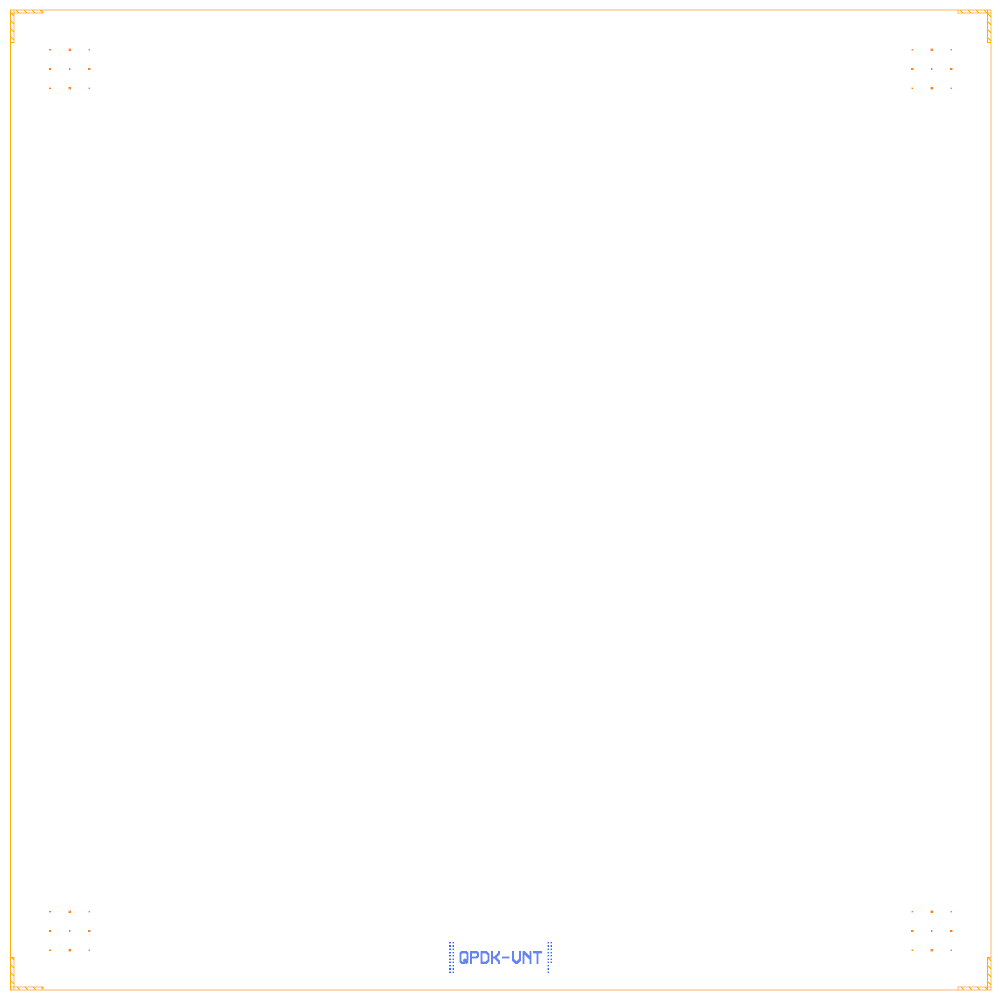

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/vortex_neck_test_chip/s1_die.png')

In [5]:
W, H = 4800, 5600                                # the source's chip area (µm)
DX, DY = 100, 2800                               # Designer = QPDK source + (DX, DY)
d = Designer("vortex_neck_test_chip", box=QP.die_box(W, H), chip={"name_chip": "QPDK-VNT"}, live=LIVE)
print("die box:", d.design.chip.box)
layout_step(d, STEPS / "s1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads: the two launchers and the pad rule

QPDK's `launcher` is a KQC-style `BondPad` here (`QP.LAUNCHER`: 200 × 200 µm pad, 110 µm gap, 100 µm taper).
**PDK rule:** the outer etch edge of a pad sits `frame.pad_edge` (100 µm) from the die edge. `edge="auto"` in
`d.add` applies it: the pad keeps its position along the nearest die edge (here the feedline's y) and slides
perpendicular to it until its etch ends 100 µm from it. In the source the pads sit on the 4.8 mm chip area's
edge, 1350 µm inside our die edges; the rule moves each 1250 µm out. The table measures the result.

The first picture is the chip so far, the second zooms on the west launcher.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PW | `BondPad` | w | 100.0 | ✓ |
| PE | `BondPad` | e | 100.0 | ✓ |

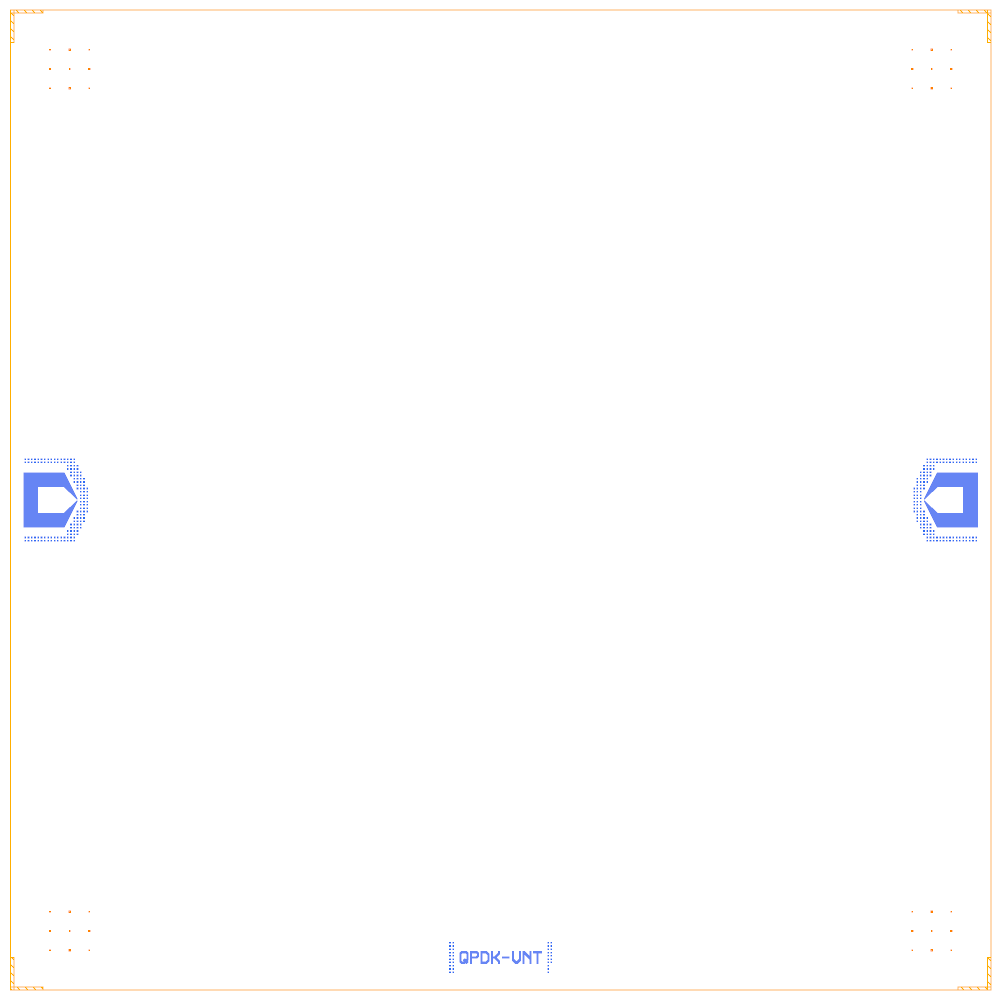

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `PW`, `PE`.

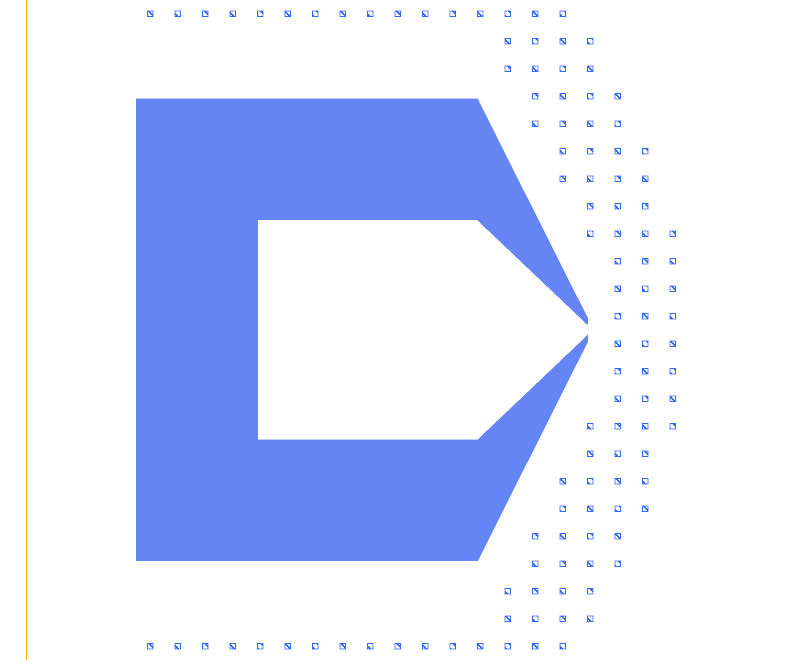

In [6]:
with d.batch():
    pw = d.add("PW", "BondPad", at=(QP.LAUNCHER_DEPTH, DY), rot=270, edge="auto", **QP.LAUNCHER)
    pe = d.add("PE", "BondPad", at=(W - QP.LAUNCHER_DEPTH, DY), rot=90, edge="auto", **QP.LAUNCHER)
rebuild(d)                                       # a live=False Designer builds on request: the table reads this build
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(1000, 1000), width=400)
x0, _, _, _ = d.design.chip.box
snap(d, STEPS / "2_pad.png", box=(x0 - 20, DY - 300, x0 + 700, DY + 300), size=(800, 660), width=360);

## Design 3 · Readout: the feedline

**The feedline** `FL` runs straight from PW to PE (CPW 10/6 µm, r = 100 µm). It needs nothing else on the chip, so it
comes first; the four resonators hang on it (Design 5). With the launchers at the die edges it is 2.5 mm longer than
the source's.

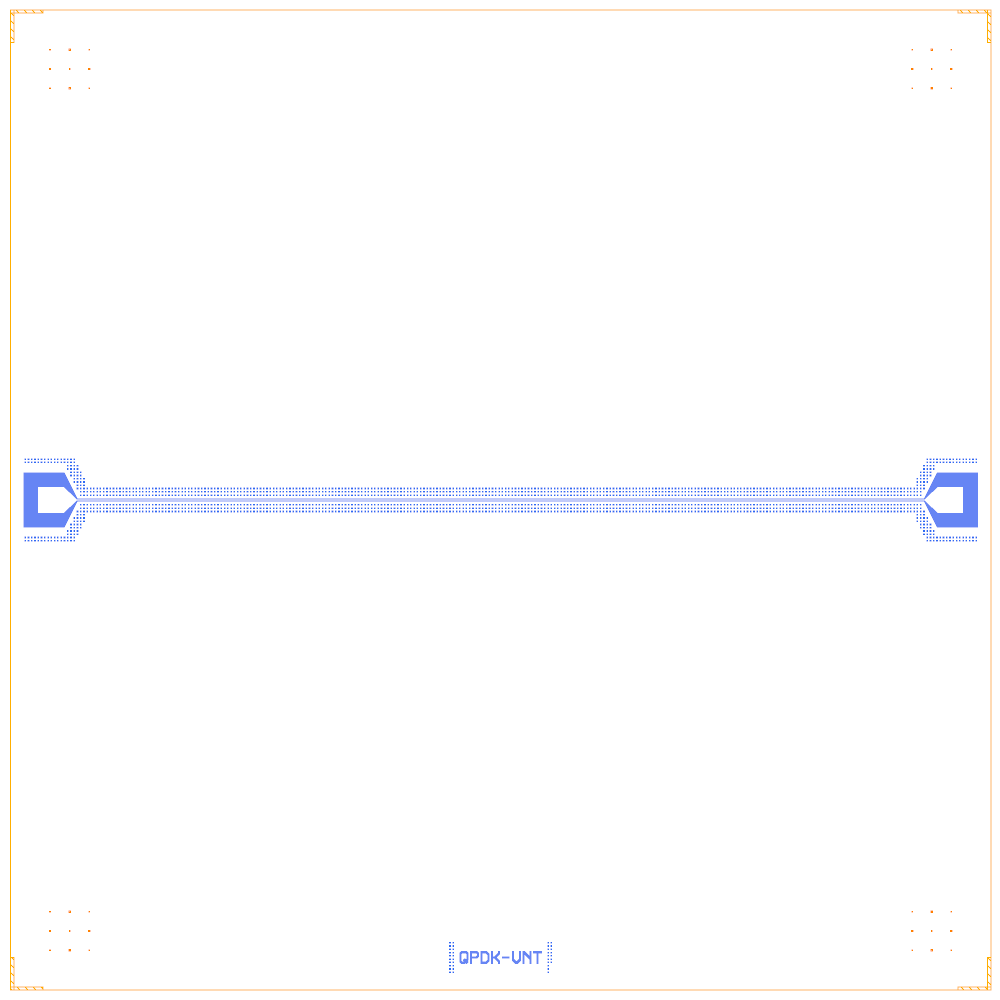

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('build/snapshots/vortex_neck_test_chip/s3_feedline.png')

In [7]:
with d.batch():
    fl = d.route("FL", pw.a, pe.a, r=QP.CPW_R)
layout_step(d, STEPS / "s3_feedline.png", size=(1000, 1000), width=400)

## Design 4 · No qubits: the four neck terminations

This chip has no qubits; its devices under test are the necks each resonator is shorted through. The four `NeckTermination`s at the source's neck placement: port `o1` at (source x, ∓2200 µm), facing the
feedline (rotation ∓90°), with the QPDK defaults (taper, 2 µm × 325 µm neck, 380 × 425 µm window, vortex-trap
holes). They are named after the resonator's length step: `p600` = 4000 + 600 µm, `m300` = 4000 − 300 µm, …

{'p600': (1643.919, 600.0, 90.00000000000001), 'm300': (2215.347, 5000.0, -90.00000000000001)}


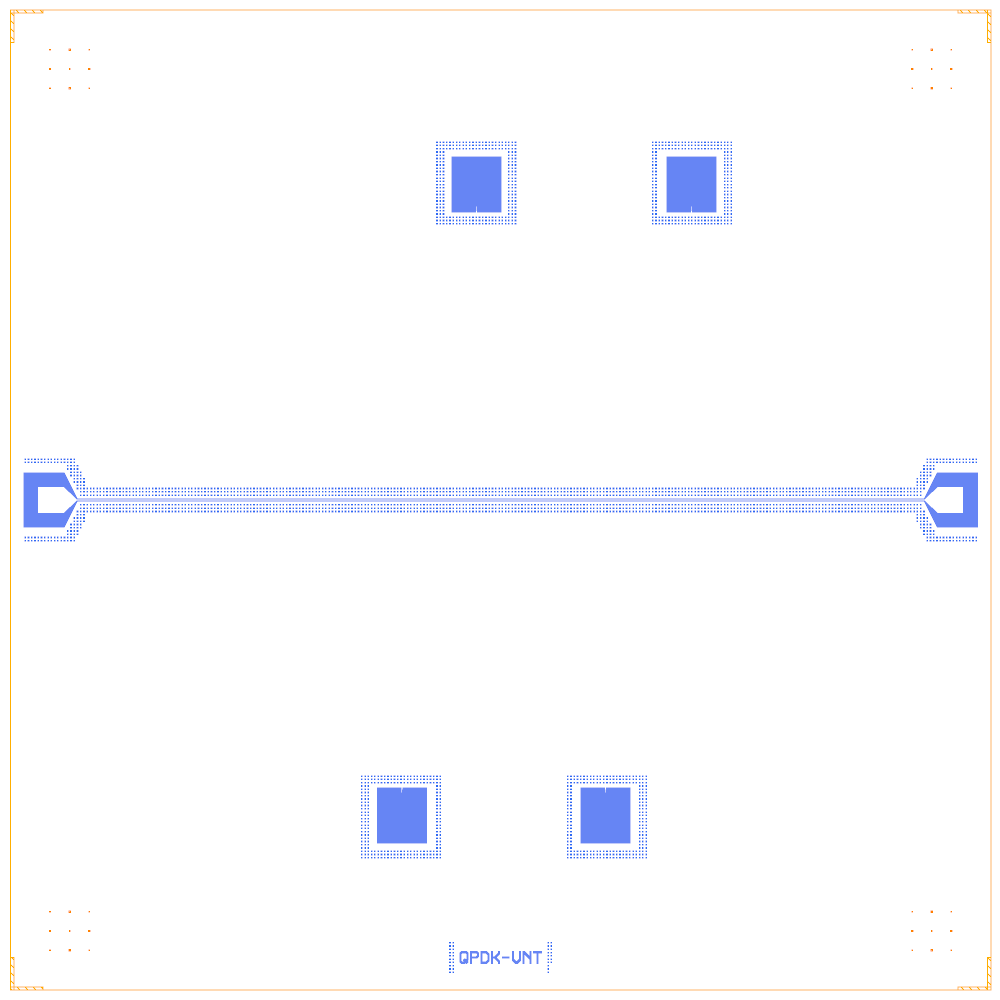

**On the chip so far:** 2 pads · 0 qubits · 4 other components · 1 routes · 0 declared couplings. **This step added** 4 component(s) `N_p600`, `N_m300`, `N_p300`, `N_0`.

WindowsPath('build/snapshots/vortex_neck_test_chip/s4_necks.png')

In [8]:
# name, length, coupled-section start (source x), neck x (source), below (-1) / above (+1) the feedline
RES = (("p600", 4600, 1006, 1543.919, -1), ("m300", 3700, 1706, 2115.347, +1),
       ("p300", 4300, 2606, 3101.061, -1), ("0", 4000, 3306, 3758.204, +1))
with d.batch():
    for name, L, x_cpl, x_neck, sgn in RES:
        d.add(f"N_{name}", "NeckTermination", at=(DX + x_neck, DY + sgn * 2200), rot=90 * sgn)
print({n: port_info(d, f"N_{n}.o1") for n in ("p600", "m300")})   # (x, y, direction °): o1 faces the feedline
layout_step(d, STEPS / "s4_necks.png", size=(1000, 1000), width=400)

## Design 5 · Readout: the four λ/4 resonators

Each resonator runs from its neck's `o1`, 400 µm towards the feedline, east along a jog to the coupled section's east
end, and into a 200 µm hanger coupler on the feedline: `fl.hanger(near=(x, y), length=200, ground_gap=8, end="open",
direction="backward")` centres the coupler at the feedline point nearest (x, y) — the source's coupled-section centre
— with an 8 µm ground strip and the open end to the west. `meander=L + LEAD` fits a 6-turn meander of the full length
(L plus the QPDK lead computed in the title cell, 1077.1 µm). Open at the hanger and shorted through the neck, each
line is a λ/4.

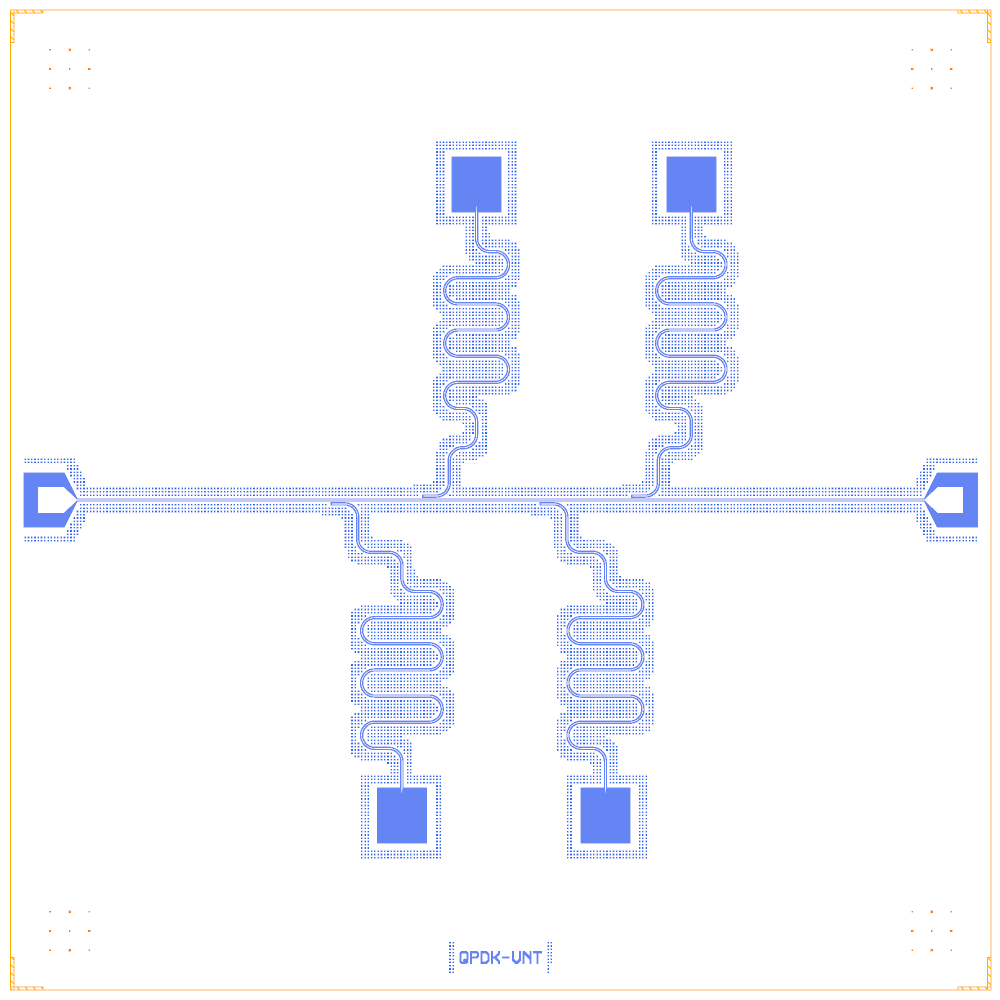

**On the chip so far:** 2 pads · 0 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** 4 route(s) `R_p600`, `R_m300`, `R_p300`, `R_0`.

lead 1077.1 µm; {'FL': 6480.0, 'R_p600': 5677.1, 'R_m300': 4777.1, 'R_p300': 5377.1, 'R_0': 5077.1}


In [9]:
R_BEND = 100.0                                   # QPDK cpw bend radius
LEAD = 150.06 + 970 - 2 * R_BEND + math.pi * R_BEND / 2   # QPDK lead resonator_o2 → neck o1 (computed above): 1077.1 µm
with d.batch():
    for name, L, x_cpl, x_neck, sgn in RES:
        xn, yn = DX + x_neck, DY + sgn * 2200
        x_east = DX + x_cpl + 200                     # east end of the coupled section (the route arrives here)
        y_jog = DY + sgn * 400
        d.route(f"R_{name}", f"N_{name}.o1",
                fl.hanger(near=(x_east - 100, DY), length=200, side="left" if sgn > 0 else "right",
                          ground_gap=8, direction="backward", end="open"),
                meander=L + LEAD, r=QP.CPW_R, nodes=[(xn, y_jog), (x_east, y_jog)]).set(meanders=6)
layout_step(d, STEPS / "s5_resonators.png", size=(1000, 1000), width=400)
print(f"lead {LEAD:.1f} µm;", {k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 6 · Coupling: only the hangers

Each resonator couples to the feedline through its open coupled section (Design 5); their coupled sections sit
700–900 µm apart along the line and alternate below and above it, so nothing else couples them.

## Design 7 · Routing: no control lines

No qubits, so no flux, drive or charge lines.

## Design 8 · The whole chip: the sim group, the centring, save

**Sim group, centring, save.** One sim group: the feedline with its four resonators and necks (eigenmode, 200 µm
margin; the feedline ends in the pads' 50 Ω ports, so each mode's Q gives κ). `center_in_die` checks that the
content sits centred in the die and shifts it if it is more than 50 µm off — here it is centred (the pads and the
alternating resonators are symmetric about the die centre), so nothing moves. Then the design is saved with `save_design`, which compares it with
the file it replaces (the previous run's): it should say *same design*, and the file keeps the previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/qpdk/vortex_neck_test_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer vortex_neck_test_chip: 6 instances, 5 routes, live=False> → examples\designs\qpdk\vortex_neck_test_chip.json


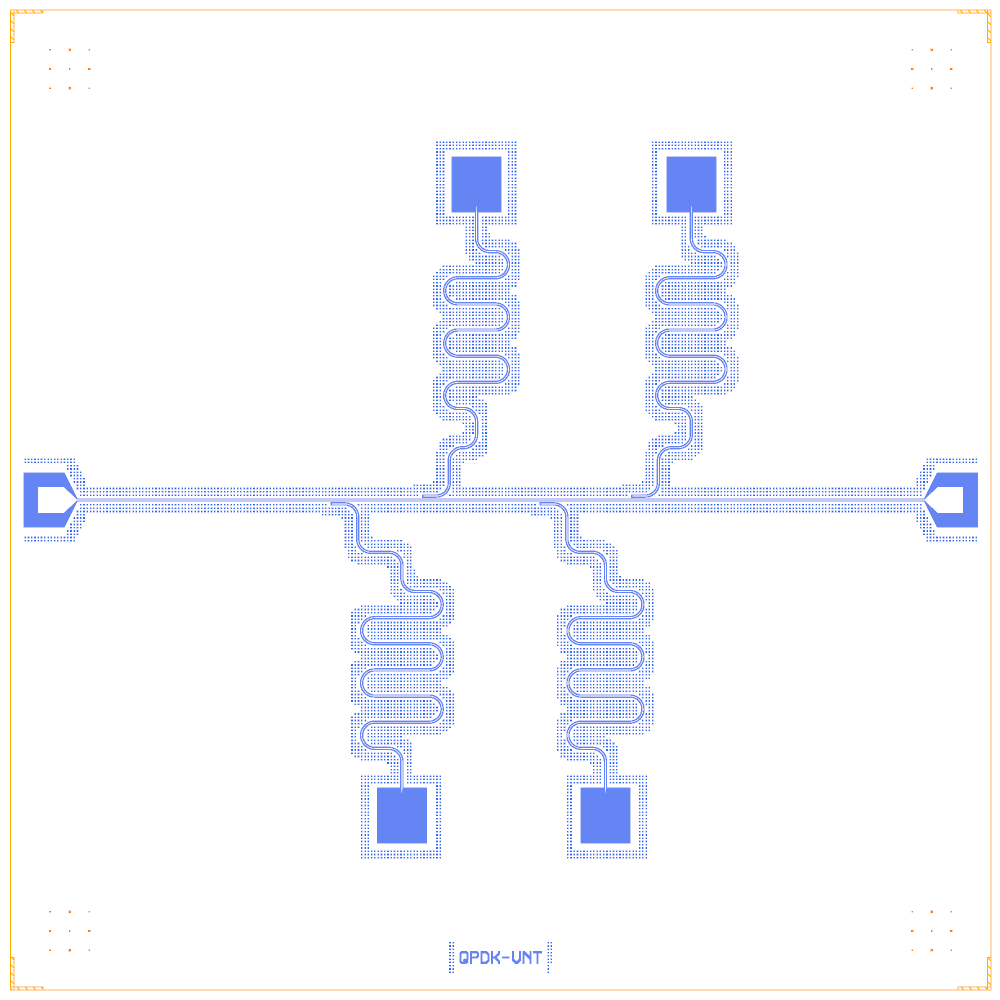

**On the chip so far:** 2 pads · 0 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/vortex_neck_test_chip/s8_chip.png')

In [10]:
ALL = ["FL"] + [f"{p}_{n}" for n in ("p600", "m300", "p300", "0") for p in ("R", "N")]
d.sim_group("ALL", ALL, margin_um=200, analyses=["eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "vortex_neck_test_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "s8_chip.png", size=(1000, 1000), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean: no errors, no warnings and no PDK design warnings (both pads at 100 µm, no junctions). `pdk_report` gives the PDK band drawn in the build, the content centred (0, 0) and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: the feedline is one node between the two 50 Ω pad ports; each
resonator route is a λ/4 `TLres`, open at the hanger end and shorted through its neck (the `NeckTermination` model
adds the taper + neck as a series line at its inductive-equivalent length); the hanger coupling is the coupled-line
capacitance to the feedline.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

The feedline with its four resonators: four linear modes (no junctions, so no anharmonicity), their frequencies
and κ into the two 50 Ω pads. The source states no targets. The 0.3 / 0.6 mm length steps keep the four modes
apart. The neck model is geometric only, so the real necks (kinetic inductance) sit lower in frequency.

In [ ]:
res = simulate_groups(d, {"ALL": ALL}, max_modes=4)
display(Markdown(modes_md(res["ALL"])))

**From the v1 run:** four resonator modes at 4.522 (R_p600), 4.726 (R_p300), 4.949 (R_0) and 5.193 GHz (R_m300), each on its own line (participation 1.00), with κ 0.017–0.026 MHz into the pads (Q_ext ≈ 2.0–2.6 × 10⁵). The LOM counts each neck as 1279 µm of 10/6 µm CPW (the builder notes in Check 2), so the four λ/4 lines are 6056–6956 µm long.

## LOM 2 · The LOM in a plot

The same results as a picture: (a) the four modes (QuCat; squares are resonators), (b) the dispersive-shift panel
stays empty: no qubits, no χ.

In [ ]:
plot_lom(res, STEPS / "lom.png", title="vortex_neck_test_chip: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The neck is this chip's subject: its inductance sets how far the shorted end sits electrically beyond the drawn
line. Widen R_0's neck from 2 to 6 µm: the neck's inductive-equivalent length shrinks, so R_0's λ/4 gets shorter and
its frequency rises; the other three resonators do not change. The change is made on a copy (`design_copy`), so
`vortex_neck_test_chip.json` keeps QPDK's 2 µm.

In [ ]:
d2 = design_copy(DESIGN)
d2["N_0"].set(neck_width=6)
after = simulate_groups(d2, {"ALL": ALL}, max_modes=4)
m0, m1 = {m.label: m for m in res["ALL"].modes}, {m.label: m for m in after["ALL"].modes}
display(Markdown("**N_0 neck width: 2 → 6 µm**\n\n| mode | f before (GHz) | f after (GHz) | Δf (MHz) | κ before (MHz) | κ after (MHz) |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {m0[k].f_GHz:.4f} | {m1[k].f_GHz:.4f} | {1e3 * (m1[k].f_GHz - m0[k].f_GHz):+.1f} | "
                     f"{m0[k].kappa_MHz:.3g} | {m1[k].kappa_MHz:.3g} |" for k in m0 if k in m1)))

**Result (from the v1 run).** R_0 moves from 4.9485 to 5.1081 GHz (+160 MHz) and its κ from 0.0225 to 0.0248 MHz; the other three modes do not move. The wider neck is a shorter inductive-equivalent line, so R_0's λ/4 is electrically shorter.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one eigenmode job for the feedline with its four resonators (the feedline ends in its pads' 50 Ω
ports, so each mode's Q gives κ). In a C-matrix the shorted λ/4 is part of ground, so there is no Q3D job.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")   # the group's own analysis: eigenmode only
display(Markdown(jobs_md(jobs_eig)))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "ALL", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: none here

The component step of the plugin is a Q3D C-matrix per group. Each λ/4 is shorted to the ground plane through its
neck, so in a C-matrix it is part of ground: there is nothing to extract, and the sim group asks for the eigenmode
only. The frequencies and κ come from the eigenmode (Simulate 3) and the driven run (Simulate 4).

## Simulate 3 · Eigenmode simulation

The feedline's box in HFSS eigenmode: its ends leave the box into the pads' 50 Ω ports, so each resonator mode's Q
gives its κ. The neck is in the geometry as drawn (taper, 2 µm neck, window, trap holes): the FEM sees its geometric
inductance, still without the kinetic one (a thin-film property the HFSS model does not have).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the feedline, where each resonator is a notch. The library cannot hand the solved
eigenmode **mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest
thing: the same sim group and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's
mode nearest R_0 (the LOM's f before the eigenmode is solved) and a fast sweep from 0.4 GHz below to 0.2 GHz above
it (R_p300's and R_0's notches).

In [ ]:
f_r0 = res["ALL"].params.get("R_0.f_GHz")                # the LOM's R_0 frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "ALL", jobs_eig["ALL"][0], keep_eig["ALL"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["ALL"]:
    display(Markdown(driven_md(keep_drv["ALL"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q (no junction: every p_J is 0), with the LOM's four resonator frequencies as dashed lines. The table below lists the
modes.

In [ ]:
lom_r = {m.label: m.f_GHz for m in res["ALL"].modes if m.kind == "resonator"}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_r)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each LOM resonator against the eigenmode it is: `match_modes` pairs them in order of frequency (the k-th lowest LOM
resonator with the k-th lowest chosen mode, Q > 100), so close neighbours cannot swap. κ = f/Q of the 50 Ω-terminated
box. The driven run adds the notch nearest R_0.

In [ ]:
fem_r = match_modes(keep_eig.get("ALL"), lom_r)
rows = []
for m in res["ALL"].modes:
    e = fem_r.get(m.label)
    kap = "–" if m.kappa_MHz is None else f"{m.kappa_MHz:.3g}"
    rows.append(f"| `{m.label}` | {m.f_GHz:.4f} | {kap} | "
                + (f"{e['f_GHz']:.4f} | {e['Q']:.3g} | {1e3 * e['f_GHz'] / e['Q']:.3g} |" if e else "– | – | – |"))
if fem_r:
    display(Markdown("| resonator | LOM f (GHz) | LOM κ (MHz) | FEM f (GHz) | FEM Q | FEM κ = f/Q (MHz) |\n"
                     "|---|---|---|---|---|---|\n" + "\n".join(rows)))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would put each resonator's LOM f and κ next to its "
          "eigenmode f, Q and κ.")
if keep_drv["ALL"]:
    print("R_0, driven notch:", driven_values(keep_drv["ALL"], "R_0", f_r0))

## Results 3 · FEM against the LOM

The LOM's f and κ of each resonator next to the eigenmode's, with the difference in %. The LOM counts each neck as
1279 µm of plain CPW (a geometric estimate, Check 2), the FEM solves the drawn neck: their difference is the first
check of the neck model. Neither has the neck's kinetic inductance, which a measurement adds on top.

In [ ]:
rows = []
for m in res["ALL"].modes:
    e = fem_r.get(m.label)
    if m.kind == "resonator" and e:
        rows += [(f"{m.label}.f_GHz", m.f_GHz, e["f_GHz"], "eigenmode"),
                 (f"{m.label}.kappa_MHz", m.kappa_MHz, 1e3 * e["f_GHz"] / e["Q"], "eigenmode, f/Q")]
if keep_drv["ALL"]:
    rows += [(k, res["ALL"].params.get(k), v, "driven S21 notch")
             for k, v in driven_values(keep_drv["ALL"], "R_0", f_r0).items()]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts each resonator's LOM f and κ next to the "
          "eigenmode's (and R_0's driven notch), with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets, so this notebook sets one as an exercise: **R_0 at 4.85 GHz**, ≈ 100 MHz below where
the LOM puts it (from the v1 run: 4.9485 GHz), still between R_p300 (4.726) and R_m300 (5.193 GHz). There is no
qubit, so `loop.feedback` (which tunes qubit–readout pairs) does not apply; the feedback is the first-order rule of a
λ/4: f ∝ 1/ℓ over the whole electrical length, the route plus the neck's equivalent line (`NECK_EQ`, 1279 µm from
the builder notes of the v1 run). On the route alone that is f ∝ ℓ_route^p with p = −ℓ_route / (ℓ_route + NECK_EQ)
(≈ −0.8), the prior of the rule; the route gets ≈ 130 µm longer (the meander takes it). When an eigenmode is kept,
the LOM is first scaled by FEM / LOM of R_0 (`SCALE`). The target goes on a copy (`target_copy` →
`build/vortex_neck_test_chip_target.json`); the revisions are copies of it.

In [ ]:
F_T, F_TOL = 4.85, 0.001                         # the exercise target for R_0 and its tolerance (GHz)
NECK_EQ = 1279.0                                 # the neck's equivalent CPW length in the LOM (Check 2, the v1 run)
DESIGN_T = target_copy(DESIGN, {"R_0": {"f_GHz": F_T}})
f_lom = lom_r["R_0"]
f_fem = (fem_r.get("R_0") or {}).get("f_GHz")
SCALE = f_fem / f_lom if f_fem else 1.0          # FEM / LOM at the drawn length (1: the LOM alone)
L0 = float(d.data["routes"]["R_0"]["length"])
P0 = -L0 / (L0 + NECK_EQ)                        # d ln f / d ln ℓ_route of a λ/4 with a fixed extra length
L1 = rule_step(L0, SCALE * f_lom, F_T, P0)
display(Markdown(f"**R_0:** now {SCALE * f_lom:.4f} GHz ({'FEM' if f_fem else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
                 f"route {L0:.1f} → **{L1:.1f} µm** (f ∝ ℓ_route^{P0:.2f})"))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the route length, its LOM runs (× `SCALE`), and the next step
uses the exponent of the last two points (a secant), until R_0 is within 1 MHz or `MAX_ITER` steps are made. With
`RUN_FEM = True` each revision's eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and the loop
closes on the FEM's R_0.

In [ ]:
def f_r0_of(k, it):
    """Revision it: R_0's route k µm; its frequency on the LOM (× SCALE), or from its own eigenmode with RUN_FEM."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["R_0"].set(meander=k)
    path = d2.save(Path("build") / f"vortex_neck_test_chip_rev{it}.json")
    r = simulate_groups(d2, {"ALL": ALL}, max_modes=4)["ALL"]
    lom_k = {m.label: m.f_GHz for m in r.modes if m.kind == "resonator"}
    if RUN_FEM:
        job = export_sims(path, ["ALL"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["ALL"]
        e = match_modes(keep, lom_k).get("R_0")
        if e:
            return e["f_GHz"], path
    return SCALE * lom_k["R_0"], path


history = rule_iterate(f_r0_of, "R_0.f_GHz", "R_0.length", L0, F_T, F_TOL, P0, max_iter=MAX_ITER,
                       start=(SCALE * f_lom, DESIGN_T), fem=bool(RUN_FEM))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `vortex_neck_test_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/qpdk/vortex_neck_test_chip.json` rebuilds `build/vortex_neck_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers (there are none),
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: the PDK band drawn in the build (the source has no fill), 5 µm holes in
3 rows round the 3/0 keep-outs and at least 4 µm from them; the necks' own vortex-trap holes are part
of the cell's etch. From the v1 run: 1/0 11 424 polygons (the etch with the necks' trap holes and the band's holes), 3/0 7735 (the keep-outs plus the band's holes); cheese source `build`, 7731 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/qpdk/vortex_neck_test_chip.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip (the pads at the die edges, the four resonators alternating below and above the feedline, the PDK
cheese band round the CPWs); the neck of R_p600 (taper, 2 µm neck, window and trap holes); its open coupled end
on the feedline; the die frame's south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and the
R_p600 neck in the **fab view** (the mask from Fab 1: 1/0 with the trap holes and the band, 3/0). The chip
boundary 100/0 is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "vortex_neck_test_chip.png", size=(1400, 1400), width=560)
xn, yn = DX + 1543.919, DY - 2200
show_snapshot(d, OUT / "vortex_neck_test_chip_short.png", box=(xn - 230, yn - 470, xn + 230, yn + 60), size=(900, 1040),
              width=420)
show_snapshot(d, OUT / "vortex_neck_test_chip_coupler.png", box=(1050, 2700, 1350, 2860), size=(1500, 800), width=480)
show_snapshot(d, OUT / "vortex_neck_test_chip_frame.png", box=(-1350, -950, -450, -50), size=(900, 900), width=300)
snap_file(Path("build") / "vortex_neck_test_chip_fab.oas", OUT / "vortex_neck_test_chip_fab_neck.png",
          box=(xn - 260, yn - 500, xn + 260, yn + 100), size=(1040, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | the netlist (feedline, four open-ended hangers, four neck shorts); the neck geometry (QPDK defaults); the neck and coupled-section positions; the resonator lengths (L + the computed 1077.1 µm lead) |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; the pads 100 µm from the die edge (1250 µm out each), so the feedline is 2.5 mm longer; sapphire and Nb instead of Al on Si; the PDK cheese band |
| **estimated** | the neck's LOM (geometric inductance only, no kinetic inductance); the meander shape |
| **PDK design warnings** | none (DRC clean) |
| layout | built in eight segments (die, launchers, feedline, necks, resonators; no coupling and no control lines; the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (R_0 4.85 GHz): the λ/4 rule on R_0's route length (the neck's equivalent length kept fixed), iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |